# 01 — Análise Exploratória de Dados

**Objetivo.** Conhecer as duas bases do desafio antes de qualquer modelagem: o que cada uma
contém, que problemas de qualidade trazem e quais atributos separam, de fato, bons e maus pagadores.

**Bases.** `application_record.csv` traz a ficha cadastral de cada solicitação de cartão
(renda, ocupação, estado civil, tempo de emprego etc.). `credit_record.csv` traz o
comportamento de pagamento mês a mês de cada conta. As duas se ligam pela coluna `ID`.

Todo gráfico tem uma leitura logo abaixo. A definição do alvo é justificada em detalhe no
notebook 02; aqui ela é usada pronta, pela função `build_dataset` de `src/preprocessing.py`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))   # permite `from src... import ...`

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from src.config import (BIN_CADASTRO, CAT_CADASTRO, COR_BOM, COR_MAU, COR_NEUTRA, GROUP,
                        NUM_CADASTRO, NUM_HISTORICO, ROTULOS)
from src.data import load_raw
from src.evaluation import information_value
from src.plots import bad_rate_bars, save, set_style
from src.preprocessing import build_dataset

# Semente fixa: usada em TODO ponto com aleatoriedade (split, modelos, CV).
RANDOM_STATE = 42

RAW = Path("..") / "data" / "raw"
PROCESSED = Path("..") / "data" / "processed"
TARGET = "MAU_PAGADOR"

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
set_style()

In [2]:
app, credit = load_raw()
print("application_record:", app.shape)
print("credit_record:     ", credit.shape)
app.head()

application_record: (438557, 18)
credit_record:      (1048575, 3)


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,"427,500.000",Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.000
1,5008805,M,Y,Y,0,"427,500.000",Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.000
2,5008806,M,Y,Y,0,"112,500.000",Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.000
3,5008808,F,N,Y,0,"270,000.000",Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.000
4,5008809,F,N,Y,0,"270,000.000",Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.000


In [3]:
credit.head(8)

,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
4,5001712,0,C
5,5001712,-1,C
6,5001712,-2,C
7,5001712,-3,C


**Leitura.** A ficha cadastral tem uma linha por solicitação e 18 colunas. O histórico tem uma
linha por conta **e por mês**: `MONTHS_BALANCE` conta os meses para trás a partir da extração
(0 = mês atual, −1 = mês anterior…) e `STATUS` é a situação da conta naquele mês.

## 1. Visão geral

In [4]:
app.info()

<class 'pandas.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  str    
 2   FLAG_OWN_CAR         438557 non-null  str    
 3   FLAG_OWN_REALTY      438557 non-null  str    
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  str    
 7   NAME_EDUCATION_TYPE  438557 non-null  str    
 8   NAME_FAMILY_STATUS   438557 non-null  str    
 9   NAME_HOUSING_TYPE    438557 non-null  str    
 10  DAYS_BIRTH           438557 non-null  int64  
 11  DAYS_EMPLOYED        438557 non-null  int64  
 12  FLAG_MOBIL           438557 non-null  int64  
 13  FLAG_WORK_PHONE      438557 non-null  int64  
 14  FLAG_PHONE           438557 non-null  int64  
 15  FLAG_EMAIL           438557 

In [5]:
app.drop(columns="ID").describe().T

,count,mean,std,min,25%,50%,75%,max
CNT_CHILDREN,"438,557.000",0.427,0.725,0.000,0.000,0.000,1.000,19.000
AMT_INCOME_TOTAL,"438,557.000","187,524.286","110,086.853","26,100.000","121,500.000","160,780.500","225,000.000","6,750,000.000"
DAYS_BIRTH,"438,557.000","-15,997.905","4,185.030","-25,201.000","-19,483.000","-15,630.000","-12,514.000","-7,489.000"
DAYS_EMPLOYED,"438,557.000","60,563.675","138,767.800","-17,531.000","-3,103.000","-1,467.000",-371.000,"365,243.000"
FLAG_MOBIL,"438,557.000",1.000,0.000,1.000,1.000,1.000,1.000,1.000
FLAG_WORK_PHONE,"438,557.000",0.206,0.405,0.000,0.000,0.000,0.000,1.000
FLAG_PHONE,"438,557.000",0.288,0.453,0.000,0.000,0.000,1.000,1.000
FLAG_EMAIL,"438,557.000",0.108,0.311,0.000,0.000,0.000,0.000,1.000
CNT_FAM_MEMBERS,"438,557.000",2.194,0.897,1.000,2.000,2.000,3.000,20.000


In [6]:
ids_app, ids_cred = set(app["ID"]), set(credit["ID"])
atributos = [c for c in app.columns if c != "ID"]
com_hist = app[app["ID"].isin(ids_cred)]
visao = pd.Series({
    "Solicitações (linhas em application_record)": len(app),
    "IDs distintos em application_record": app["ID"].nunique(),
    "IDs repetidos com fichas diferentes": int(app["ID"].duplicated().sum()),
    "Fichas cadastrais distintas (17 atributos)": len(app.drop_duplicates(atributos)),
    "Contas em credit_record": len(ids_cred),
    "Contas com ficha E histórico": len(ids_app & ids_cred),
    "Fichas distintas entre as contas com histórico": len(com_hist.drop_duplicates(atributos)),
})
visao.to_frame("quantidade")

,quantidade
Solicitações (linhas em application_record),438557
IDs distintos em application_record,438510
IDs repetidos com fichas diferentes,47
Fichas cadastrais distintas (17 atributos),90085
Contas em credit_record,45985
Contas com ficha E histórico,36457
Fichas distintas entre as contas com histórico,9728


**Leitura — três achados que moldam todo o projeto.**

1. **Só 8% das solicitações têm histórico.** Das 438.557 fichas, apenas 36.457 aparecem em
   `credit_record`. As demais não têm comportamento observado e, portanto, não podem ser
   rotuladas como boas ou más: ficam fora da modelagem.
2. **O `ID` identifica a conta, não a pessoa.** As 36.457 contas com histórico correspondem a
   apenas 9.728 fichas distintas. Fichas idênticas nos 17 atributos, inclusive data de
   nascimento e de admissão medidas em dias, são a mesma pessoa com várias contas (3,7 em
   média). Se isso for ignorado, a mesma pessoa aparece no treino e no teste e o modelo é
   premiado por decorar fichas. O notebook 03 mede o tamanho desse efeito.
3. **47 IDs aparecem duas vezes com fichas diferentes.** Não há como saber qual é a correta;
   nenhum deles tem histórico de crédito, então a remoção não custa nada.

Um detalhe sobre a fonte: `credit_record.csv` tem exatamente 1.048.575 linhas, o limite de
linhas de uma planilha Excel menos o cabeçalho. É um indício forte de que o arquivo foi
truncado na origem, ou seja, o histórico de parte das contas pode estar incompleto.

In [7]:
significado = {"X": "sem dívida no mês", "C": "quitado no mês", "0": "1–29 dias de atraso",
               "1": "30–59 dias", "2": "60–89 dias", "3": "90–119 dias",
               "4": "120–149 dias", "5": "150+ dias / baixa a prejuízo"}
status = credit["STATUS"].value_counts().reindex(list(significado)).to_frame("meses")
status["significado"] = status.index.map(significado)
status["% dos meses"] = 100 * status["meses"] / status["meses"].sum()
status

,meses,significado,% dos meses
STATUS,,,
X,209230,sem dívida no mês,19.954
C,442031,quitado no mês,42.155
0,383120,1–29 dias de atraso,36.537
1,11090,30–59 dias,1.058
2,868,60–89 dias,0.083
3,320,90–119 dias,0.031
4,223,120–149 dias,0.021
5,1693,150+ dias / baixa a prejuízo,0.161


**Leitura.** Em 99% dos meses a conta está quitada, sem dívida ou com atraso inferior a 30
dias. Atrasos de 30–59 dias são 1,1% dos meses e atrasos de 60 dias ou mais somam apenas
0,3%. O evento que queremos prever é raro, e isso vai aparecer como forte desbalanceamento
de classes (seção 6).

## 2. A tabela de modelagem

A partir daqui a análise usa a tabela que vai para os modelos: **uma linha por conta**, com a
ficha já limpa, os atributos derivados e o alvo `MAU_PAGADOR` (1 = a conta atrasou 60 dias ou
mais em algum dos seus 12 primeiros meses de vida). As regras e a justificativa de cada
decisão estão no notebook 02.

In [8]:
df = build_dataset(app, credit)
print(df.shape, "| clientes distintos:", df[GROUP].nunique())
df.head()

(24566, 32) | clientes distintos: 7946


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,ID_CLIENTE,AGE_YEARS,FLAG_NO_JOB,YEARS_EMPLOYED,INCOME_PER_MEMBER,EMPLOYED_SHARE,OPEN_MONTH,MONTHS_OBSERVED,WORST_STATUS_WINDOW,MAU_PAGADOR,HIST_N_ACCOUNTS,HIST_MONTHS,HIST_WORST_STATUS,HIST_MONTHS_30PLUS,HIST_SHARE_LATE,HIST_LAST_STATUS,HIST_HAS
0,5008804,0,1,1,0,"427,500.000",Working,Higher education,Civil marriage,Rented apartment,1,0,0,Not informed,2,C000000,32.870,0,12.440,"213,750.000",0.837,-15,16,1,0,0,0,-1,0,0.000,-1,0
1,5008805,0,1,1,0,"427,500.000",Working,Higher education,Civil marriage,Rented apartment,1,0,0,Not informed,2,C000000,32.870,0,12.440,"213,750.000",0.837,-14,15,1,0,1,1,-1,0,0.000,-1,1
2,5008806,0,1,1,0,"112,500.000",Working,Secondary / secondary special,Married,House / apartment,0,0,0,Security staff,2,C000001,58.790,0,3.100,"56,250.000",0.076,-29,30,0,0,0,0,-1,0,0.000,-1,0
3,5008810,1,0,1,0,"270,000.000",Commercial associate,Secondary / secondary special,Single / not married,House / apartment,0,1,1,Sales staff,1,C000002,52.320,0,8.350,"270,000.000",0.243,-26,27,0,0,1,12,0,0,0.500,-1,1
4,5008811,1,0,1,0,"270,000.000",Commercial associate,Secondary / secondary special,Single / not married,House / apartment,0,1,1,Sales staff,1,C000002,52.320,0,8.350,"270,000.000",0.243,-38,39,0,0,0,0,-1,0,0.000,-1,0


**Leitura.** Restam 24.566 contas de 7.946 clientes distintos, porque só entram contas com
pelo menos 12 meses de histórico observado. As colunas `HIST_*` resumem o comportamento do
mesmo cliente em contas **anteriores** à solicitação.

## 3. Distribuição das variáveis

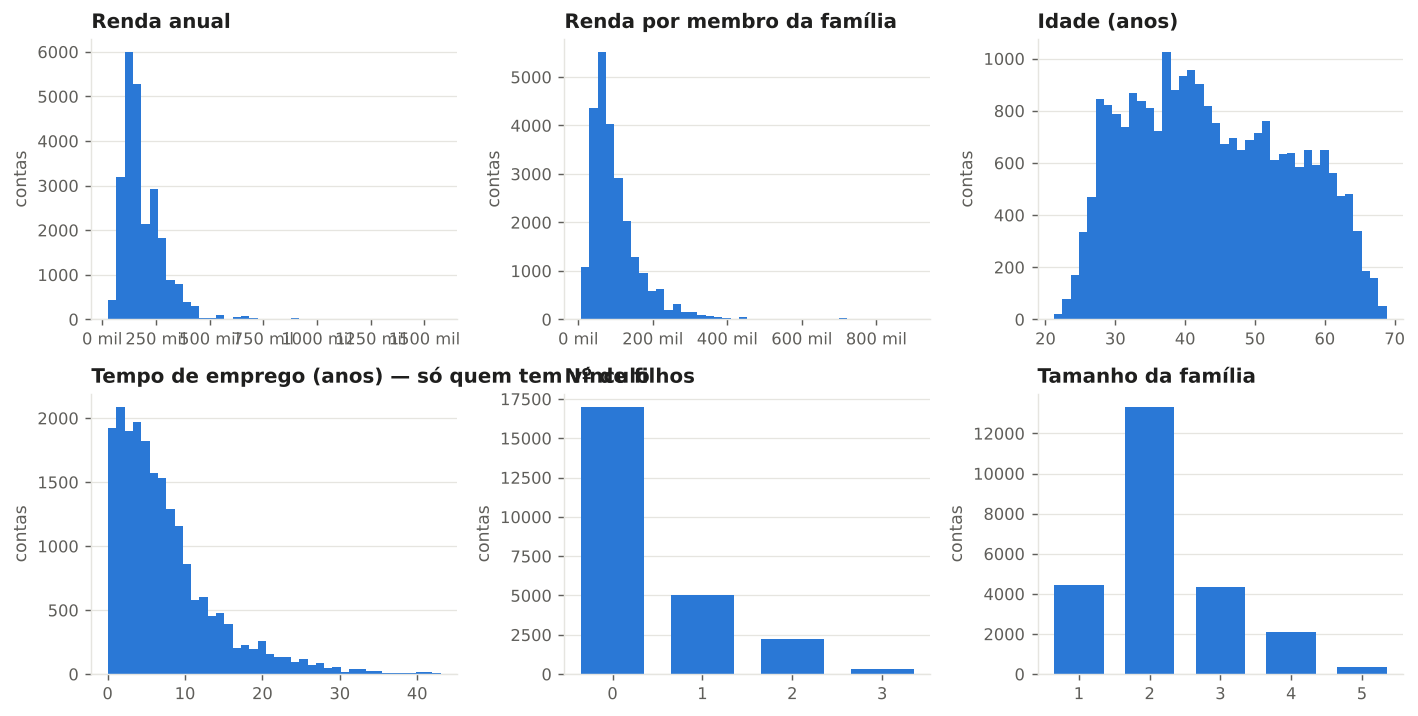

,count,mean,std,min,25%,50%,75%,max,assimetria
CNT_CHILDREN,"24,566.000",0.426,0.713,0.000,0.000,0.000,1.000,3.000,1.583
CNT_FAM_MEMBERS,"24,566.000",2.207,0.883,1.000,2.000,2.000,3.000,5.000,0.800
AMT_INCOME_TOTAL,"24,566.000","189,099.020","102,368.006","27,000.000","121,500.000","162,000.000","225,000.000","1,575,000.000",2.448
INCOME_PER_MEMBER,"24,566.000","100,745.138","72,563.573","7,560.000","56,250.000","78,750.000","123,750.000","900,000.000",2.635
AGE_YEARS,"24,566.000",43.946,11.265,21.240,34.560,42.780,53.190,68.860,0.191
YEARS_EMPLOYED,"24,566.000",6.322,6.600,0.000,1.260,4.590,8.938,43.020,1.692
EMPLOYED_SHARE,"24,566.000",0.292,0.268,0.000,0.061,0.227,0.457,1.000,0.826


In [9]:
num_plot = ["AMT_INCOME_TOTAL", "INCOME_PER_MEMBER", "AGE_YEARS", "YEARS_EMPLOYED",
            "CNT_CHILDREN", "CNT_FAM_MEMBERS"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for ax, col in zip(axes.ravel(), num_plot):
    x = df[col]
    if col in ("CNT_CHILDREN", "CNT_FAM_MEMBERS"):
        cont = x.value_counts().sort_index()
        ax.bar(cont.index.astype(str), cont.values, color=COR_BOM, width=0.7)
    elif col == "YEARS_EMPLOYED":
        ax.hist(x[df["FLAG_NO_JOB"] == 0], bins=40, color=COR_BOM)
    else:
        ax.hist(x, bins=40, color=COR_BOM)
    ax.set_title(ROTULOS[col])
    ax.set_ylabel("contas")
    ax.grid(axis="x", visible=False)
axes[0, 0].xaxis.set_major_formatter(lambda v, _: f"{v/1e3:.0f} mil")
axes[0, 1].xaxis.set_major_formatter(lambda v, _: f"{v/1e3:.0f} mil")
axes[1, 0].set_title("Tempo de emprego (anos) — só quem tem vínculo")
fig.tight_layout()
save(fig, "01_distribuicoes_numericas")
plt.show()
df[NUM_CADASTRO].describe().T.assign(assimetria=df[NUM_CADASTRO].skew())

**Leitura.**
- **Renda** tem cauda longa à direita (assimetria 2,4): mediana de 162 mil, média de 189 mil
  e máximo de 1,6 milhão. A renda por membro da família herda a mesma forma. Modelos
  sensíveis à escala recebem essas variáveis em log (notebook 02).
- **Idade** se espalha de 21 a 69 anos, quase simétrica, com média de 44.
- **Tempo de emprego** também é assimétrico: metade dos clientes com vínculo tem menos de
  seis anos no emprego atual. 16% das contas são de pessoas sem vínculo (aposentados).
- **Filhos e família**: 69% não têm filhos e 54% vivem em família de duas pessoas. As
  contagens foram truncadas em 3 filhos e 5 membros (ver seção 5).

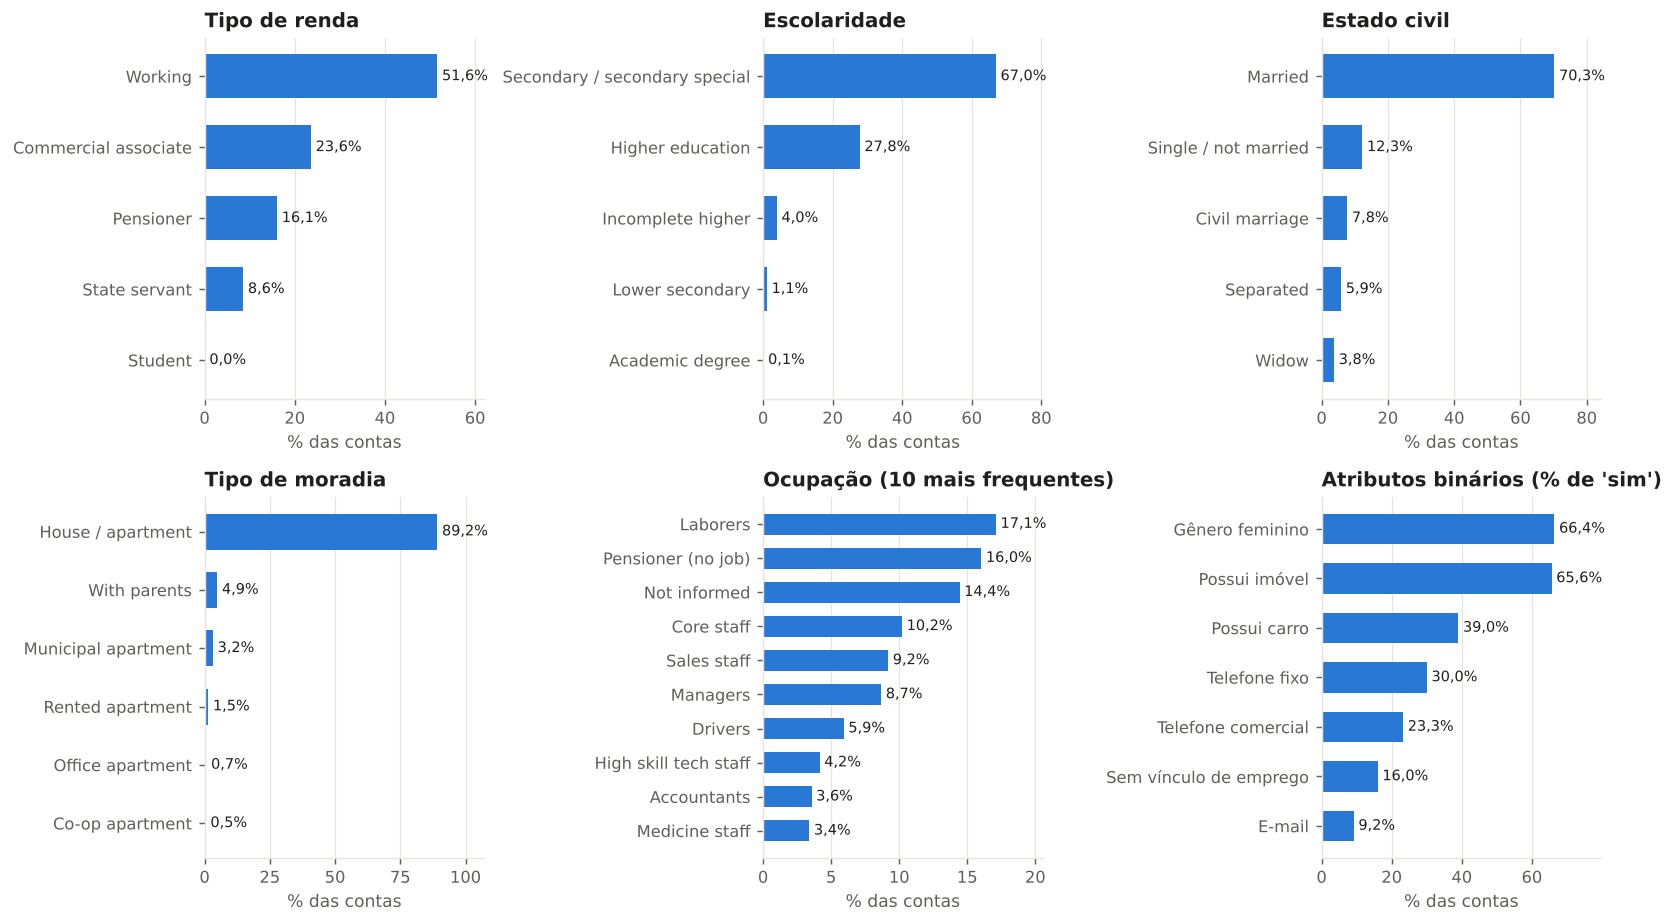

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(12.5, 7.2))
for ax, col in zip(axes.ravel(), CAT_CADASTRO + ["BINARIAS"]):
    if col == "BINARIAS":
        s = (100 * df[BIN_CADASTRO].mean()).sort_values()
        s.index = [ROTULOS[c] if c != "CODE_GENDER" else "Gênero feminino" for c in s.index]
        titulo = "Atributos binários (% de 'sim')"
    else:
        s = (100 * df[col].value_counts(normalize=True)).sort_values().tail(10)
        titulo = ROTULOS[col] + (" (10 mais frequentes)" if df[col].nunique() > 10 else "")
    ax.barh(s.index, s.values, color=COR_BOM, height=0.62)
    for yi, v in enumerate(s.values):
        ax.text(v, yi, f" {v:.1f}%".replace(".", ","), va="center", fontsize=8)
    ax.set_xlim(0, s.max() * 1.2)
    ax.set_title(titulo)
    ax.set_xlabel("% das contas")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "01_distribuicoes_categoricas")
plt.show()

**Leitura.** A carteira é pouco diversa em vários atributos: 89% moram em casa ou
apartamento, 70% são casados, 67% têm ensino médio e 52% são assalariados. Dois terços das contas
são de mulheres. Categorias como "Student", "Academic degree" ou "Co-op apartment" têm
pouquíssimas contas; no pré-processamento, categorias com menos de 1% do treino são
agrupadas, para o modelo não aprender regra a partir de um punhado de casos.

## 4. Correlações

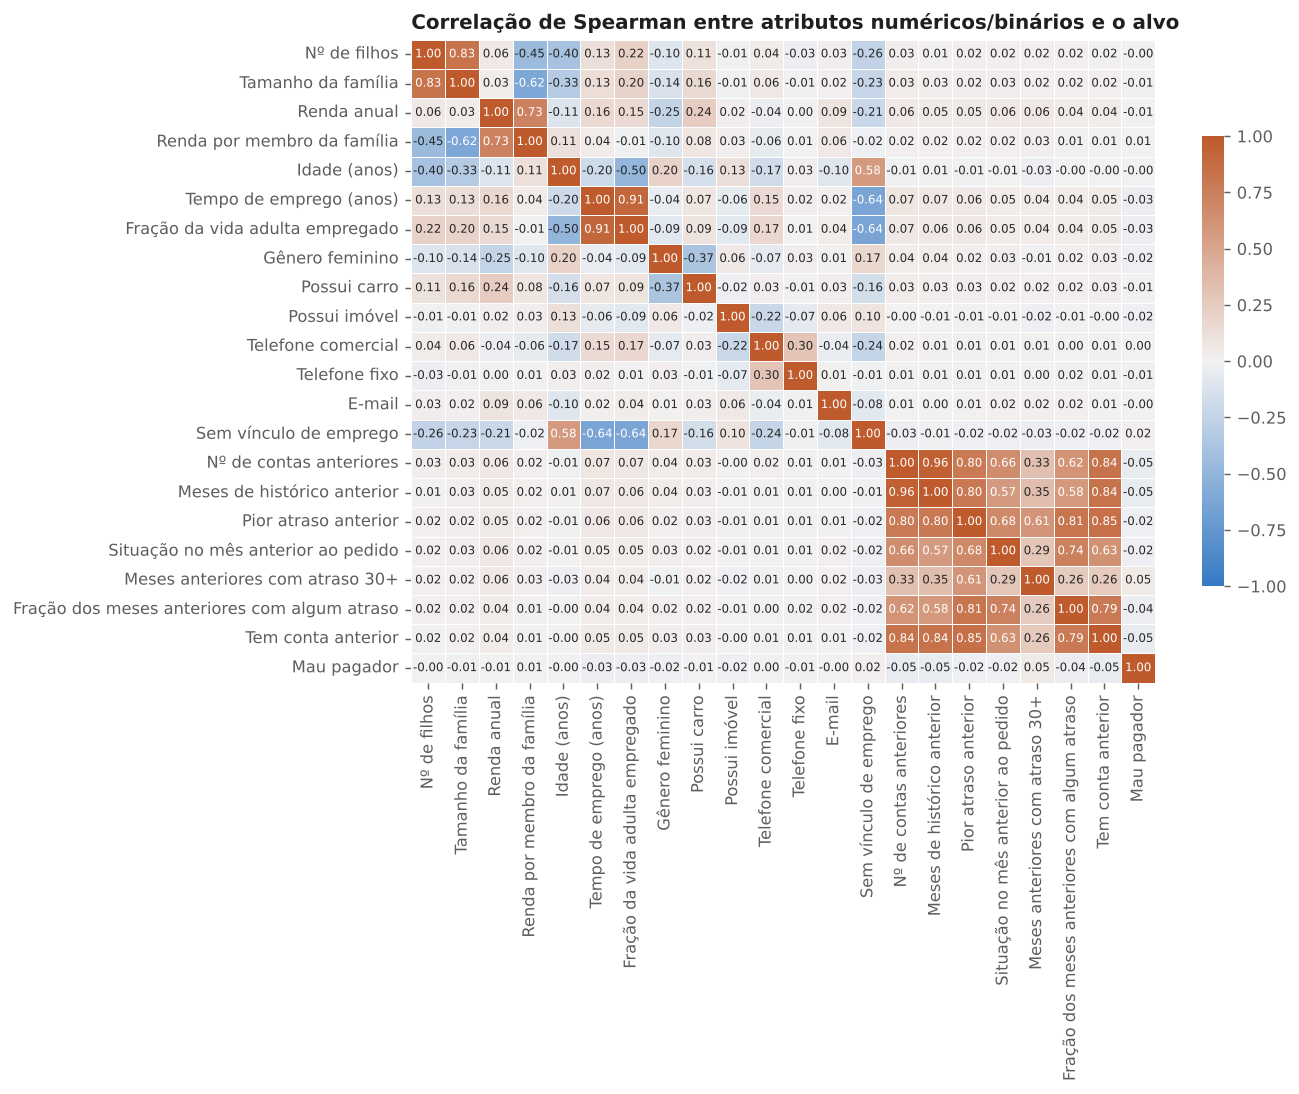

In [11]:
cols_corr = NUM_CADASTRO + BIN_CADASTRO + NUM_HISTORICO + ["HIST_HAS", TARGET]
corr = df[cols_corr].corr(method="spearman")
nomes = ["Gênero feminino" if c == "CODE_GENDER" else ROTULOS.get(c, "Mau pagador")
         for c in cols_corr]
fig, ax = plt.subplots(figsize=(10.5, 8.5))
sns.heatmap(corr, cmap=sns.diverging_palette(250, 25, s=85, l=50, as_cmap=True), center=0,
            vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 6.5}, linewidths=0.5,
            linecolor="white", xticklabels=nomes, yticklabels=nomes, cbar_kws={"shrink": 0.7},
            ax=ax)
ax.set_title("Correlação de Spearman entre atributos numéricos/binários e o alvo")
ax.grid(False)
ax.tick_params(axis="x", rotation=90)
fig.tight_layout()
save(fig, "01_correlacoes")
plt.show()

In [12]:
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("spearman").reset_index())
pares = pares[(pares["level_0"] != TARGET) & (pares["level_1"] != TARGET)]
pares["abs"] = pares["spearman"].abs()
display(pares.sort_values("abs", ascending=False).head(10).drop(columns="abs")
        .rename(columns={"level_0": "atributo_1", "level_1": "atributo_2"}))
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).to_frame("spearman com o alvo")

,atributo_1,atributo_2,spearman
323,HIST_N_ACCOUNTS,HIST_MONTHS,0.957
116,YEARS_EMPLOYED,EMPLOYED_SHARE,0.915
372,HIST_WORST_STATUS,HIST_HAS,0.846
328,HIST_N_ACCOUNTS,HIST_HAS,0.843
350,HIST_MONTHS,HIST_HAS,0.839
1,CNT_CHILDREN,CNT_FAM_MEMBERS,0.831
371,HIST_WORST_STATUS,HIST_SHARE_LATE,0.815
346,HIST_MONTHS,HIST_WORST_STATUS,0.800
324,HIST_N_ACCOUNTS,HIST_WORST_STATUS,0.795
438,HIST_SHARE_LATE,HIST_HAS,0.788


,spearman com o alvo
HIST_MONTHS_30PLUS,0.053
HIST_HAS,-0.053
HIST_N_ACCOUNTS,-0.052
HIST_MONTHS,-0.048
HIST_SHARE_LATE,-0.036
YEARS_EMPLOYED,-0.035
EMPLOYED_SHARE,-0.030
HIST_LAST_STATUS,-0.022
CODE_GENDER,-0.021
FLAG_OWN_REALTY,-0.020


**Leitura — correlações entre atributos.**
- **Nº de contas anteriores × meses de histórico (0,96)** e as demais variáveis `HIST_*` entre
  si (0,6 a 0,85): todas medem a mesma coisa de ângulos diferentes — quanto o banco já conhece
  o cliente. Boa parte dessa correlação vem dos 34% de contas sem histórico, em que todas
  valem zero ao mesmo tempo.
- **Tempo de emprego × fração da vida adulta empregado (0,91)**: a segunda é derivada da
  primeira; carregam informação quase igual.
- **Nº de filhos × tamanho da família (0,83)**: família é, na prática, filhos mais um ou dois
  adultos.
- **Renda × renda por membro (0,73)** e **tamanho da família × renda por membro (−0,62)**:
  consequência direta da fórmula.
- **Sem vínculo × tempo de emprego (−0,64)** e **sem vínculo × idade (0,58)**: quem não tem
  vínculo é aposentado, logo mais velho e com tempo de emprego zerado.
- **Gênero × possui carro (−0,37)**: homens declaram carro com mais frequência.

Redundância não atrapalha modelos de árvore, mas instabiliza os coeficientes da regressão
logística. Por isso ela usa regularização (parâmetro `C`), ajustada no notebook 03.

**Leitura — correlação com o alvo.** Nenhum atributo passa de |0,05|. Com um evento de 1,5%
isso é esperado: um coeficiente de correlação mal consegue se mover. As taxas de maus por
categoria (seção 7) mostram melhor onde está o sinal.

## 5. Outliers

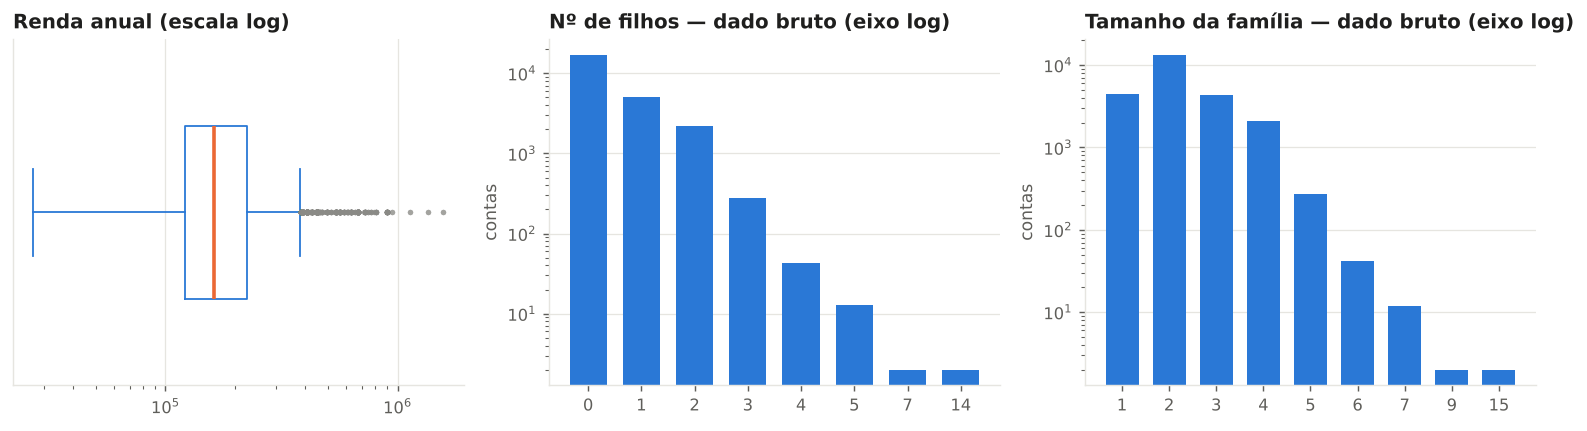

Renda: limite de Tukey (Q3 + 1,5·IQR) = 380,250; 4.4% das contas acima; máximo = 1,575,000
DAYS_EMPLOYED = 365243 (≈ 1.000 anos no futuro): 3,939 contas, todas de aposentados: True
Filhos > 3: 60 contas | família > 5: 58 contas
Taxa de maus com renda acima do limite: 1.65% (n=1,092) vs. 1.50% no restante


In [13]:
bruto = app[app["ID"].isin(df["ID"])]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].boxplot(bruto["AMT_INCOME_TOTAL"], orientation="horizontal", widths=0.5,
                flierprops=dict(marker="o", ms=3, alpha=0.4, markerfacecolor=COR_NEUTRA,
                                markeredgecolor="none"),
                medianprops=dict(color=COR_MAU, lw=2), boxprops=dict(color=COR_BOM),
                whiskerprops=dict(color=COR_BOM), capprops=dict(color=COR_BOM))
axes[0].set_xscale("log")
axes[0].set_yticks([])
axes[0].set_title("Renda anual (escala log)")
for ax, col in zip(axes[1:], ["CNT_CHILDREN", "CNT_FAM_MEMBERS"]):
    cont = bruto[col].astype(int).value_counts().sort_index()
    ax.bar(cont.index.astype(str), cont.values, color=COR_BOM, width=0.7)
    ax.set_yscale("log")
    ax.set_title(f"{ROTULOS[col]} — dado bruto (eixo log)")
    ax.set_ylabel("contas")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "01_outliers")
plt.show()

q1, q3 = bruto["AMT_INCOME_TOTAL"].quantile([0.25, 0.75])
lim = q3 + 1.5 * (q3 - q1)
print(f"Renda: limite de Tukey (Q3 + 1,5·IQR) = {lim:,.0f}; "
      f"{(bruto['AMT_INCOME_TOTAL'] > lim).mean():.1%} das contas acima; máximo = "
      f"{bruto['AMT_INCOME_TOTAL'].max():,.0f}")
print(f"DAYS_EMPLOYED = 365243 (≈ 1.000 anos no futuro): {(bruto['DAYS_EMPLOYED'] == 365243).sum():,} "
      f"contas, todas de aposentados: "
      f"{(bruto.loc[bruto['DAYS_EMPLOYED'] == 365243, 'NAME_INCOME_TYPE'] == 'Pensioner').all()}")
print(f"Filhos > 3: {(bruto['CNT_CHILDREN'] > 3).sum()} contas | família > 5: "
      f"{(bruto['CNT_FAM_MEMBERS'] > 5).sum()} contas")
alta = df["AMT_INCOME_TOTAL"] > lim
print(f"Taxa de maus com renda acima do limite: {df.loc[alta, TARGET].mean():.2%} "
      f"(n={alta.sum():,}) vs. {df.loc[~alta, TARGET].mean():.2%} no restante")

**Leitura e decisão.**
- **Renda**: 4,4% das contas ficam acima do limite de Tukey (380 mil), mas são valores
  plausíveis, não erros, e a taxa de maus nesse grupo (1,65%) é praticamente a mesma do
  restante (1,50%). **Decisão: manter**, aplicando log nos modelos lineares para a cauda não
  dominar a escala.
- **`DAYS_EMPLOYED = 365243`**: não é outlier, é um código. Marca 3.939 contas, todas de
  aposentados sem vínculo. **Decisão:** vira o indicador `FLAG_NO_JOB = 1` e tempo de emprego
  zero.
- **Filhos e família**: há registros com até 19 filhos e 20 membros na base completa. Na
  amostra de modelagem são 60 contas com mais de 3 filhos e 58 com família maior que 5.
  **Decisão: truncar** (winsorizar) em 3 e 5. Remover descartaria clientes reais; manter
  deixaria meia dúzia de casos extremos esticando a escala.

## 6. Balanceamento de classes

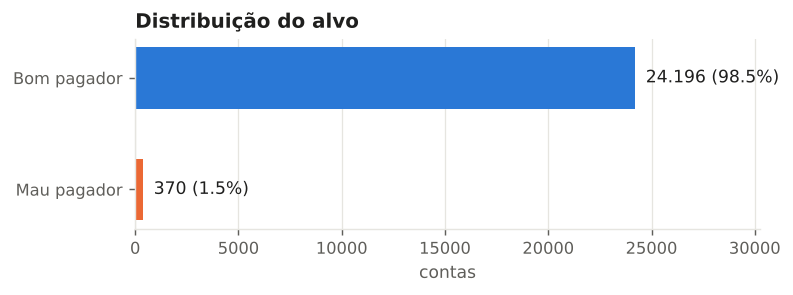

Razão bons : maus = 65 : 1
Clientes distintos: 7,946; com ao menos uma conta má: 278 (3.5%)


,contas,%
MAU_PAGADOR,,
Bom pagador,24196,98.494
Mau pagador,370,1.506


In [14]:
bal = df[TARGET].value_counts().rename({0: "Bom pagador", 1: "Mau pagador"}).to_frame("contas")
bal["%"] = 100 * bal["contas"] / bal["contas"].sum()
fig, ax = plt.subplots(figsize=(6.2, 1.9))
ax.barh(bal.index[::-1], bal["contas"][::-1], color=[COR_MAU, COR_BOM], height=0.55)
for yi, (n, p) in enumerate(zip(bal["contas"][::-1], bal["%"][::-1])):
    ax.text(n, yi, f"  {n:,} ({p:.1f}%)".replace(",", "."), va="center")
ax.set_xlim(0, bal["contas"].max() * 1.25)
ax.set_title("Distribuição do alvo")
ax.set_xlabel("contas")
ax.grid(axis="y", visible=False)
save(fig, "01_balanceamento")
plt.show()
print(f"Razão bons : maus = {bal['contas'].iloc[0] / bal['contas'].iloc[1]:.0f} : 1")
por_cliente = df.groupby(GROUP)[TARGET].max()
print(f"Clientes distintos: {len(por_cliente):,}; com ao menos uma conta má: "
      f"{por_cliente.sum():,} ({por_cliente.mean():.1%})")
bal

**Leitura.** São 370 maus pagadores em 24.566 contas: **1,5%**, ou 65 bons para cada mau. Por
cliente, 278 de 7.946 (3,5%) têm ao menos uma conta má. Três consequências:

1. **Acurácia não serve.** Aprovar todo mundo acerta 98,5% das vezes e não barra ninguém. As
   métricas certas olham para a ordenação (AUC-ROC, KS) e para a classe rara (precisão,
   recall, F1, PR-AUC).
2. **O treino precisa compensar o desbalanceamento.** Usamos pesos de classe, e não SMOTE: os
   pesos não criam registros sintéticos nem correm o risco de replicar linhas antes do split.
3. **Há pouco evento para aprender e para medir.** Com 370 maus, cada fold de validação tem
   cerca de 60. As métricas oscilam bastante de fold para fold, o que exige validação
   repetida e intervalos de confiança (notebooks 03 e 04).

## 7. Atributos × alvo

In [15]:
linhas = []
for col in NUM_CADASTRO + BIN_CADASTRO + CAT_CADASTRO + NUM_HISTORICO + ["HIST_HAS"]:
    if col in CAT_CADASTRO or df[col].nunique() <= 2:
        tab = pd.crosstab(df[col], df[TARGET])
        teste, p = "qui-quadrado", stats.chi2_contingency(tab)[1]
    else:
        teste = "Mann-Whitney"
        p = stats.mannwhitneyu(df.loc[df[TARGET] == 1, col], df.loc[df[TARGET] == 0, col]).pvalue
    linhas.append({"atributo": ROTULOS[col], "coluna": col,
                   "origem": "histórico" if col.startswith("HIST_") else "cadastro",
                   "IV": information_value(df, col, TARGET), "teste": teste, "p_valor": p})
iv = pd.DataFrame(linhas).sort_values("IV", ascending=False).reset_index(drop=True)
iv["força"] = pd.cut(iv["IV"], [-1, 0.02, 0.1, 0.3, 99], labels=["inútil", "fraca", "média", "forte"])
iv.to_csv(Path("..") / "results" / "metrics" / "information_value.csv", index=False)
iv.assign(p_valor=iv["p_valor"].map("{:.1e}".format))

,atributo,coluna,origem,IV,teste,p_valor,força
0,Pior atraso anterior,HIST_WORST_STATUS,histórico,0.845,Mann-Whitney,7.9e-03,forte
1,Situação no mês anterior ao pedido,HIST_LAST_STATUS,histórico,0.270,Mann-Whitney,5.9e-04,média
2,Tem conta anterior,HIST_HAS,histórico,0.176,qui-quadrado,1.3e-16,média
3,Meses de histórico anterior,HIST_MONTHS,histórico,0.167,Mann-Whitney,4.4e-14,média
4,Nº de contas anteriores,HIST_N_ACCOUNTS,histórico,0.148,Mann-Whitney,2.5e-16,média
5,Ocupação,OCCUPATION_TYPE,cadastro,0.137,qui-quadrado,1.0e-04,média
6,Fração dos meses anteriores com algum atraso,HIST_SHARE_LATE,histórico,0.131,Mann-Whitney,1.7e-08,média
7,Meses anteriores com atraso 30+,HIST_MONTHS_30PLUS,histórico,0.114,Mann-Whitney,7.9e-17,média
8,Tempo de emprego (anos),YEARS_EMPLOYED,cadastro,0.099,Mann-Whitney,4.5e-08,fraca
9,Estado civil,NAME_FAMILY_STATUS,cadastro,0.073,qui-quadrado,6.1e-07,fraca


O *Information Value* (IV) resume em um número o quanto a distribuição de um atributo difere
entre bons e maus. A régua usual em crédito: abaixo de 0,02 o atributo é inútil; de 0,02 a
0,1, fraco; de 0,1 a 0,3, médio; acima de 0,3, forte. Os p-valores vêm de qui-quadrado
(categóricas e binárias) e Mann-Whitney (numéricas). Eles supõem observações independentes,
o que não vale aqui (várias contas por cliente), então servem como indicação e não como
prova: o julgamento final é a validação fora da amostra no notebook 03.

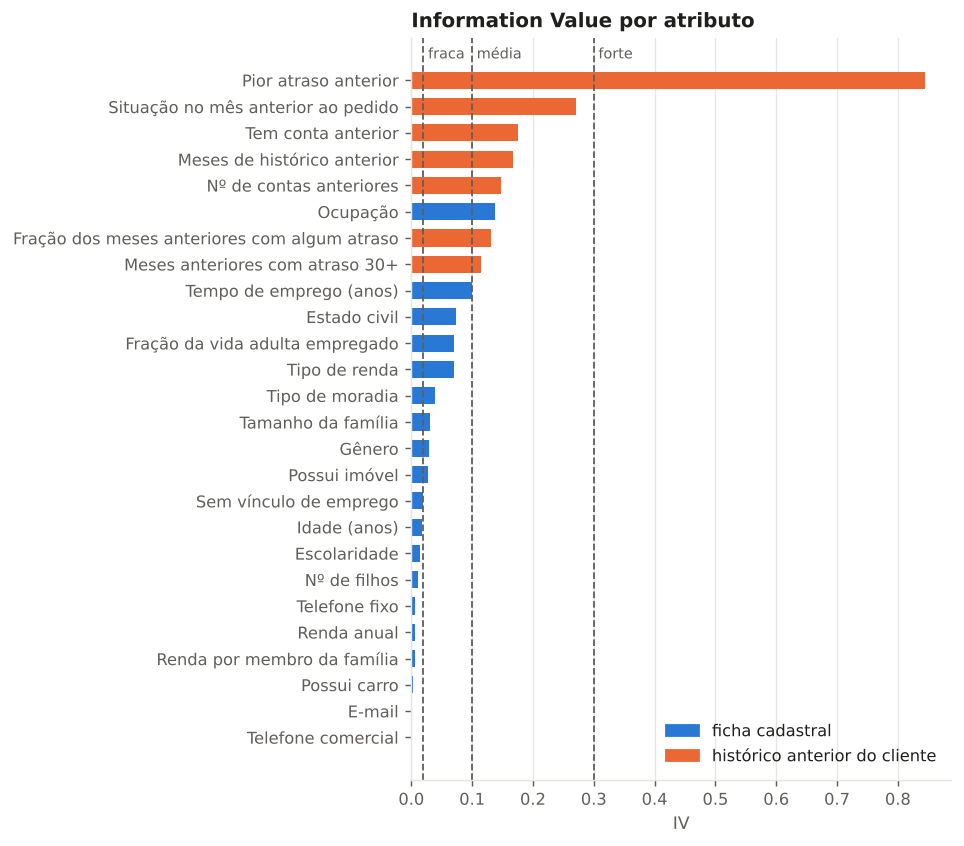

In [16]:
fig, ax = plt.subplots(figsize=(7.5, 6.6))
ordem = iv.sort_values("IV")
ax.barh(ordem["atributo"], ordem["IV"],
        color=[COR_MAU if o == "histórico" else COR_BOM for o in ordem["origem"]], height=0.65)
for x, rot in [(0.02, "fraca"), (0.1, "média"), (0.3, "forte")]:
    ax.axvline(x, color="#5f5e5a", lw=1, ls="--")
    ax.text(x, len(ordem) - 0.3, f" {rot}", fontsize=8, color="#5f5e5a", va="bottom")
ax.set_title("Information Value por atributo")
ax.set_xlabel("IV")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COR_BOM, label="ficha cadastral"),
                   Patch(color=COR_MAU, label="histórico anterior do cliente")], loc="lower right")
fig.tight_layout()
save(fig, "01_information_value")
plt.show()

**Leitura.** Dois grupos de atributos, com forças muito diferentes:

- **Histórico anterior do cliente (laranja)** concentra o sinal. *Pior atraso anterior* é o
  único atributo forte (IV 0,85) e as demais variáveis de histórico ficam na faixa média.
- **Ficha cadastral (azul)** é fraca quase por inteiro. Só *ocupação* chega à faixa média
  (0,14), e com ressalva: são 19 categorias, várias pequenas, o que infla o IV. *Tempo de
  emprego*, *estado civil* e *tipo de renda* são fracos; **renda, idade, escolaridade, filhos,
  carro, telefone e e-mail ficam abaixo de 0,02**, ou seja, não distinguem bons de maus.

É o achado central da EDA: os dados cadastrais, sozinhos, dizem pouco sobre quem vai
atrasar. O que mais informa é como a pessoa já se comportou.

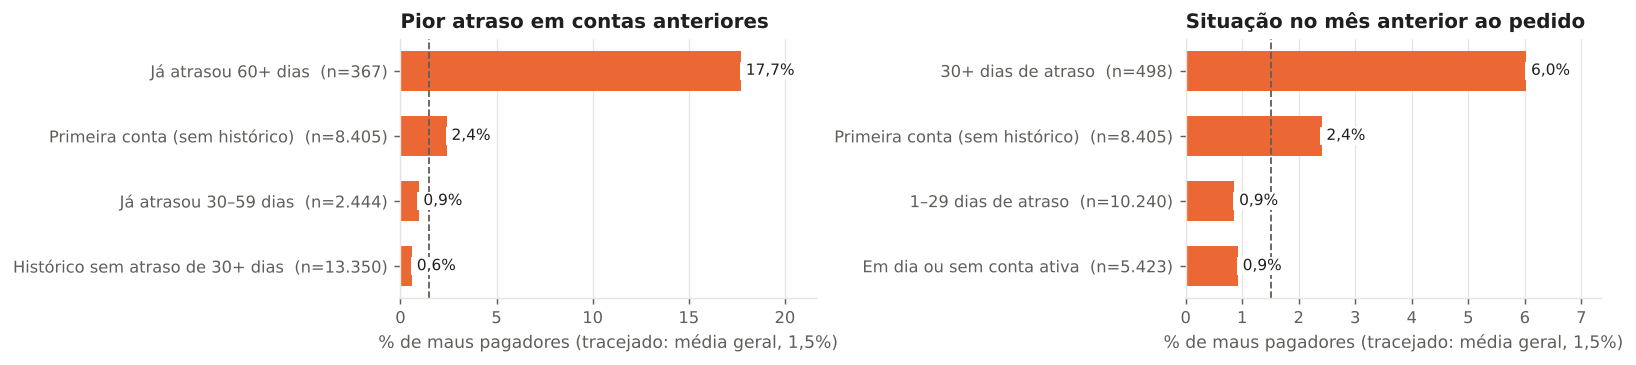

In [17]:
df["_hist"] = np.select(
    [df["HIST_HAS"] == 0, df["HIST_WORST_STATUS"] <= 0, df["HIST_WORST_STATUS"] == 1],
    ["Primeira conta (sem histórico)", "Histórico sem atraso de 30+ dias",
     "Já atrasou 30–59 dias"], default="Já atrasou 60+ dias")
df["_ultimo"] = np.select(
    [df["HIST_HAS"] == 0, df["HIST_LAST_STATUS"] == -1, df["HIST_LAST_STATUS"] == 0],
    ["Primeira conta (sem histórico)", "Em dia ou sem conta ativa", "1–29 dias de atraso"],
    default="30+ dias de atraso")
fig, axes = plt.subplots(1, 2, figsize=(12.5, 2.9))
bad_rate_bars(df, "_hist", TARGET, ax=axes[0], titulo="Pior atraso em contas anteriores",
              ordem=["Já atrasou 60+ dias", "Primeira conta (sem histórico)",
                     "Já atrasou 30–59 dias", "Histórico sem atraso de 30+ dias"])
bad_rate_bars(df, "_ultimo", TARGET, ax=axes[1], titulo="Situação no mês anterior ao pedido",
              ordem=["30+ dias de atraso", "Primeira conta (sem histórico)",
                     "1–29 dias de atraso", "Em dia ou sem conta ativa"])
fig.tight_layout()
save(fig, "01_taxa_maus_historico")
plt.show()

**Leitura.** Quem já atrasou 60 dias ou mais em outra conta volta a atrasar em **17,7%** dos
casos, doze vezes a média de 1,5%. No extremo oposto, clientes com histórico sem atraso
relevante ficam em 0,6%. Quem pede a primeira conta fica no meio (2,4%): o banco ainda não
sabe quem é. Atraso anterior de 30–59 dias não aumenta o risco (0,9%), coerente com a taxa de
rolagem do notebook 02, que mostra que a maioria desses atrasos se regulariza. O painel da
direita conta a mesma história com a foto do mês anterior ao pedido: quem estava com 30+
dias de atraso em outra conta tem 6,0% de maus.

São grupos pequenos (367 e 498 contas), mas é onde o risco se concentra.

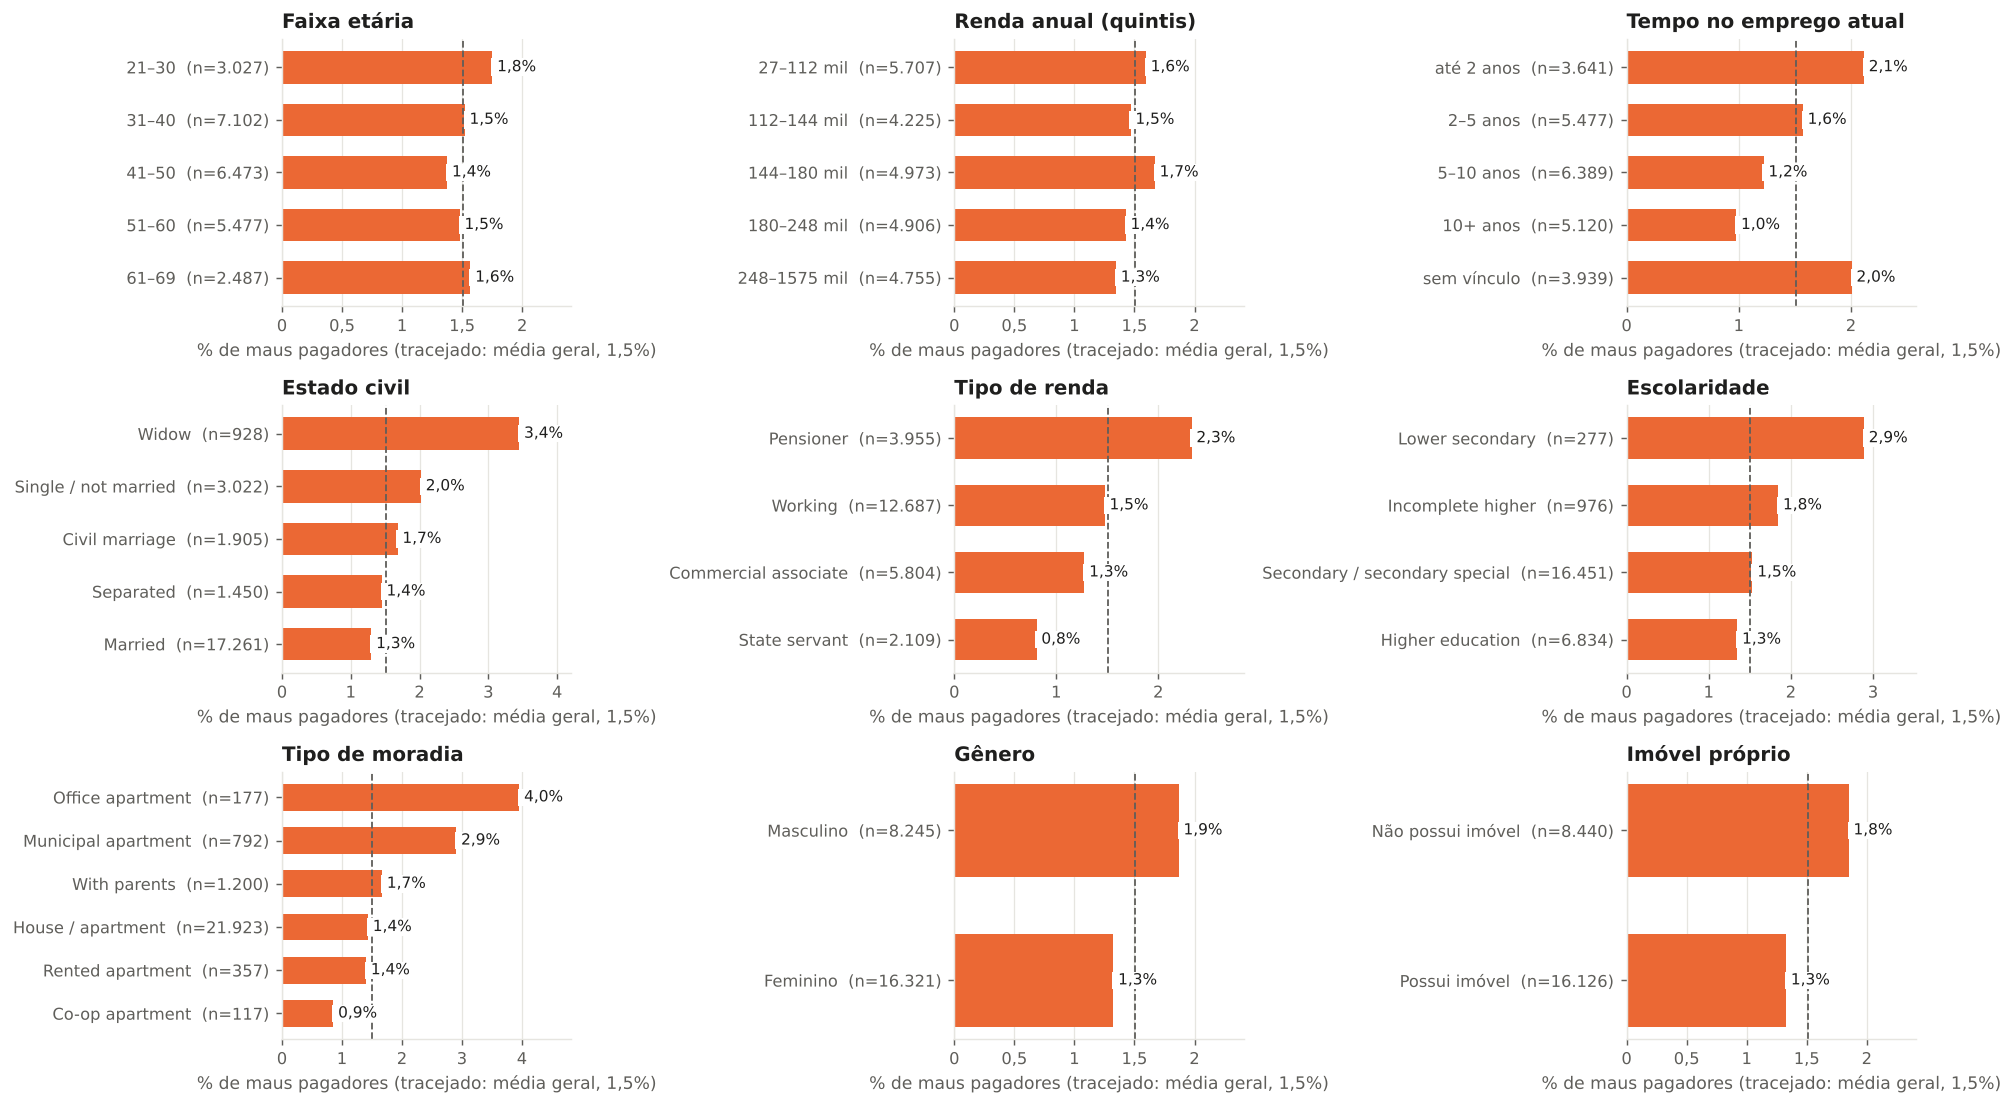

In [18]:
df["_idade"] = pd.cut(df["AGE_YEARS"], [20, 30, 40, 50, 60, 70],
                      labels=["21–30", "31–40", "41–50", "51–60", "61–69"])
df["_renda"] = pd.qcut(df["AMT_INCOME_TOTAL"], 5).map(
    lambda i: f"{i.left/1e3:.0f}–{i.right/1e3:.0f} mil").astype(str)
df["_emprego"] = np.where(df["FLAG_NO_JOB"] == 1, "sem vínculo",
                          pd.cut(df["YEARS_EMPLOYED"], [-0.1, 2, 5, 10, 50],
                                 labels=["até 2 anos", "2–5 anos", "5–10 anos", "10+ anos"]).astype(str))
df["_genero"] = df["CODE_GENDER"].map({1: "Feminino", 0: "Masculino"})
df["_imovel"] = df["FLAG_OWN_REALTY"].map({1: "Possui imóvel", 0: "Não possui imóvel"})
paineis = [("_idade", "Faixa etária", ["21–30", "31–40", "41–50", "51–60", "61–69"]),
           ("_renda", "Renda anual (quintis)", None),
           ("_emprego", "Tempo no emprego atual",
            ["até 2 anos", "2–5 anos", "5–10 anos", "10+ anos", "sem vínculo"]),
           ("NAME_FAMILY_STATUS", "Estado civil", None),
           ("NAME_INCOME_TYPE", "Tipo de renda", None),
           ("NAME_EDUCATION_TYPE", "Escolaridade", None),
           ("NAME_HOUSING_TYPE", "Tipo de moradia", None),
           ("_genero", "Gênero", None), ("_imovel", "Imóvel próprio", None)]
fig, axes = plt.subplots(3, 3, figsize=(15, 8.6))
for ax, (col, titulo, ordem) in zip(axes.ravel(), paineis):
    if col == "_renda":
        ordem = sorted(df["_renda"].unique(), key=lambda s: float(s.split("–")[0]))
    bad_rate_bars(df, col, TARGET, ax=ax, titulo=titulo, ordem=ordem, min_n=100)
fig.tight_layout()
save(fig, "01_taxa_maus_cadastro")
plt.show()

**Leitura.** Na ficha cadastral as diferenças existem, mas são modestas; quase tudo fica entre
1% e 2%.
- **Tempo no emprego atual** é o padrão mais limpo: 2,1% de maus com até 2 anos, caindo de
  forma contínua até 1,0% com mais de 10 anos. Quem não tem vínculo (aposentados) fica em 2,0%.
- **Estado civil**: viúvos (3,4%) e solteiros (2,0%) acima da média; casados abaixo (1,3%).
- **Tipo de renda**: servidores públicos têm a menor taxa (0,8%); aposentados, a maior (2,3%).
- **Moradia**: apartamento funcional (4,0%) e municipal (2,9%) acima da média, mas com poucas
  contas (177 e 792).
- **Escolaridade**: só o grupo com fundamental (2,9%, 277 contas) se destaca.
- **Gênero e imóvel**: homens 1,9% contra 1,3% das mulheres; sem imóvel 1,8% contra 1,3%.
- **Renda e idade**: sem tendência. Os cinco quintis de renda ficam entre 1,3% e 1,7%, sem
  ordem; nas faixas etárias, só os mais jovens (1,8%) saem um pouco da média.

O ponto contraintuitivo: **renda não separa bons de maus nesta base.** Quem ganha mais não
atrasa menos.

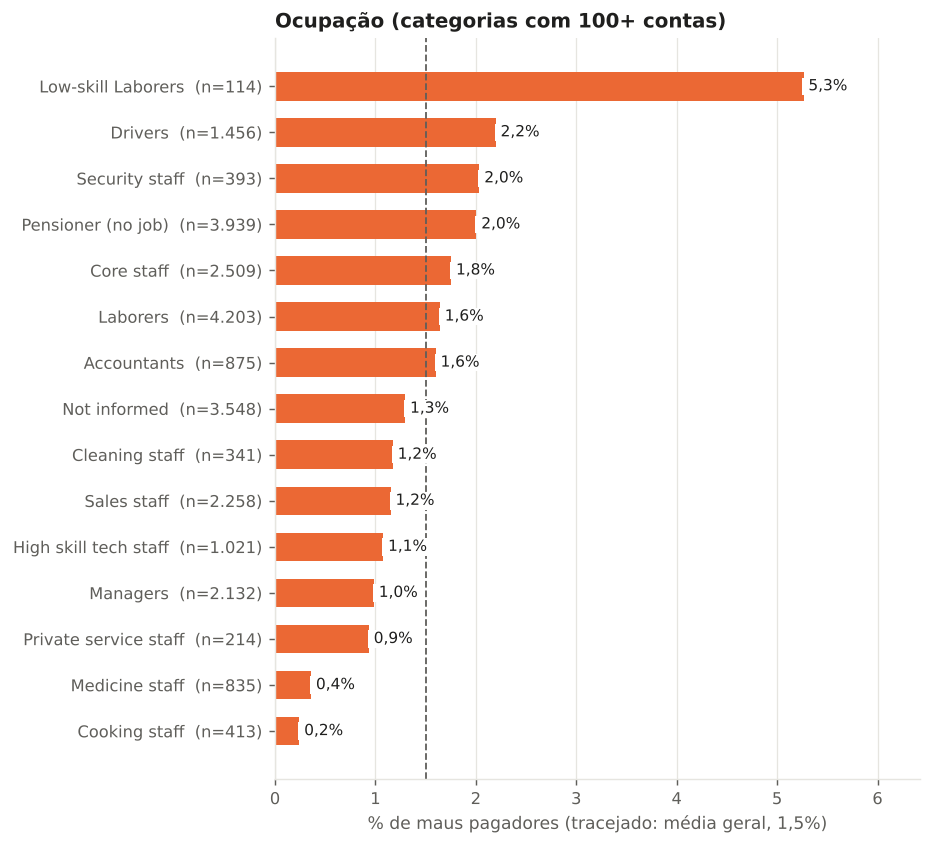

In [19]:
bad_rate_bars(df, "OCCUPATION_TYPE", TARGET, min_n=100,
              titulo="Ocupação (categorias com 100+ contas)")
save(plt.gcf(), "01_taxa_maus_ocupacao")
plt.show()

**Leitura.** A ocupação espalha as taxas de 0,2% (cozinha) a 5,3% (operários de baixa
qualificação), mas os extremos têm poucas contas: 1 mau em 413 e 6 em 114. Entre os grupos
grandes, motoristas (2,2%) e aposentados sem vínculo (2,0%) ficam acima da média, e gerentes
(1,0%) e vendas (1,2%), abaixo. A ocupação "não informada" (1,3%) não é sinal de risco.

## 8. Síntese da EDA

1. **A unidade de análise é a conta, mas a pessoa se repete.** 24.566 contas vêm de 7.946
   clientes. Todo split e toda validação precisam manter as contas de um cliente do mesmo
   lado, ou o resultado sai inflado.
2. **Mau pagador é evento raro: 1,5%.** Isso define as métricas (AUC-ROC, KS, PR-AUC,
   precisão e recall, e não acurácia), o tratamento (pesos de classe) e o cuidado com a
   incerteza das medidas.
3. **A ficha cadastral discrimina pouco.** Renda, idade, escolaridade, filhos, carro e
   contatos não separam bons de maus. Tempo de emprego, estado civil, tipo de renda,
   ocupação e moradia separam um pouco.
4. **O comportamento anterior discrimina bastante.** Quem já atrasou 60+ dias em outra conta
   tem 17,7% de maus, contra 0,6% de quem tem histórico limpo e 2,4% de quem é cliente novo.
5. **Qualidade dos dados.** Um único atributo com nulos (ocupação, 31%), um código disfarçado
   de valor (`DAYS_EMPLOYED = 365243`), uma coluna constante (`FLAG_MOBIL`), contagens
   extremas de filhos e família e 47 IDs duplicados. O tratamento de cada um está no
   notebook 02.

A hipótese que os próximos notebooks testam: um modelo só com a ficha terá poder modesto, e
acrescentar o histórico anterior do cliente deve melhorá-lo de forma relevante.